# Term-Deposit Subscription Model — Bank Telemarketing Targeting

**Business question.** A Portuguese bank runs phone campaigns to sell term deposits. Most calls fail and every call costs agent time.
*Which customers should we call first?*

**What this notebook does**
1. Explores the data and identifies a **target leak** (`duration`, the call length, is only known after the call).
2. Builds leakage-free scikit-learn pipelines and compares 6 models (baseline → logistic regression → KNN → decision tree → random forest → XGBoost) with stratified 5-fold cross-validated hyper-parameter search.
3. Evaluates on an untouched hold-out set with **ranking metrics** (ROC-AUC, PR-AUC), **calibration**, and **business metrics**: cumulative gains / lift and an expected-profit curve for choosing how many customers to call.
4. Explains the final model with **SHAP**.
5. Quantifies how much the leaky feature would have inflated results.

**Data.**  ~11k customers, 16 features, balanced target (`deposit` yes/no).

> Results summary: see the README

## 1. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))       

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_score)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBClassifier
import shap

from src.features import (TARGET, LEAKY_COLS, load_data, make_pipeline,
                          add_contact_features)
from src.evaluation import score_table, gains_table, profit_curve

SEED = 42
DATA_PATH = "../data/bank_01.pkl"   
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

d:\python\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data overview

In [2]:
df = load_data(DATA_PATH)
print(df.shape)
df.head()

(11000, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
})
overview

,dtype,n_unique,n_missing
age,int64,76,0
job,object,11,236
marital,object,3,0
education,object,3,800
default,object,2,0
balance,int64,3783,0
housing,object,2,0
loan,object,2,0
contact,object,3,0
day,int64,31,0


In [4]:
y_all = (df[TARGET] == "yes").astype(int)
print(f"Subscription rate: {y_all.mean():.1%}  (n = {len(df):,})")
print(f"Never contacted before (pdays == -1): {(df['pdays'] == -1).mean():.1%}")

Subscription rate: 47.5%  (n = 11,000)
Never contacted before (pdays == -1): 74.6%


**Observations**
- The target is roughly balanced, so accuracy is not misleading here — but the business cares about *ranking* customers, so ROC-AUC / PR-AUC and lift are the main metrics.
- `job` and `education` have a few missing values; they are imputed as their own `"unknown"` category (missingness itself may carry signal).
- `pdays = -1` is a sentinel for "never contacted", not a number of days. It is split into a `contacted_before` flag plus a numeric `pdays` where -1 → NaN (see `src/features.py`).

## 3. Exploratory analysis — what drives conversion?

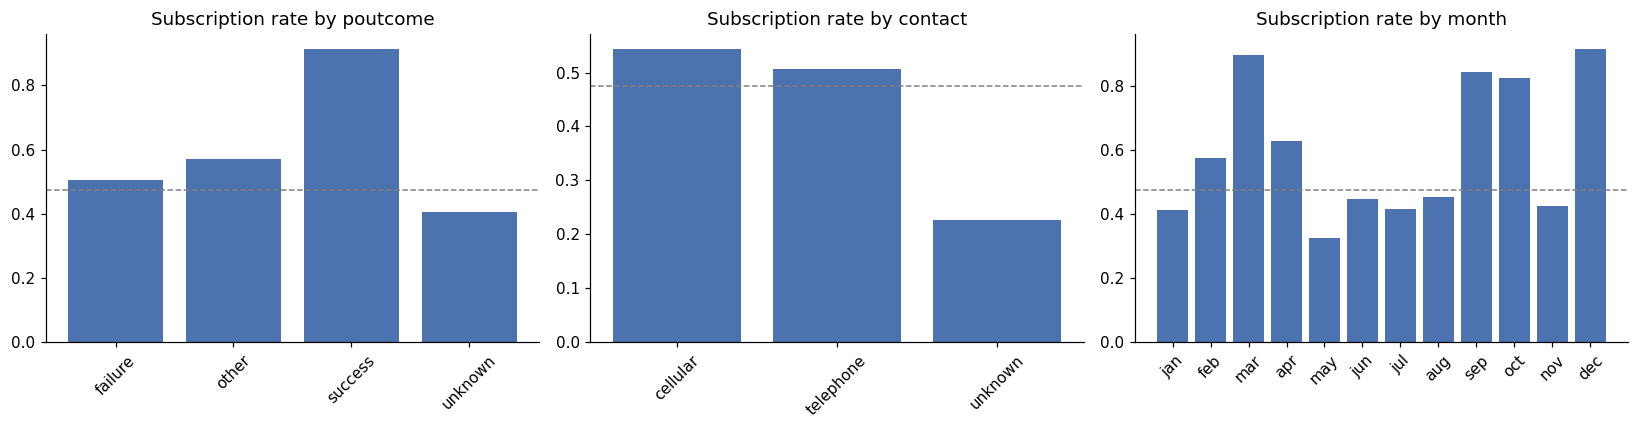

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"] if col == "month" else None
    rate = df.assign(y=y_all).groupby(col)["y"].agg(["mean", "size"])
    if order: rate = rate.reindex([m for m in order if m in rate.index])
    ax.bar(rate.index.astype(str), rate["mean"], color="#4C72B0")
    ax.axhline(y_all.mean(), ls="--", c="grey", lw=1)
    ax.set_title(f"Subscription rate by {col}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_conversion_rates.png", bbox_inches="tight"); plt.show()

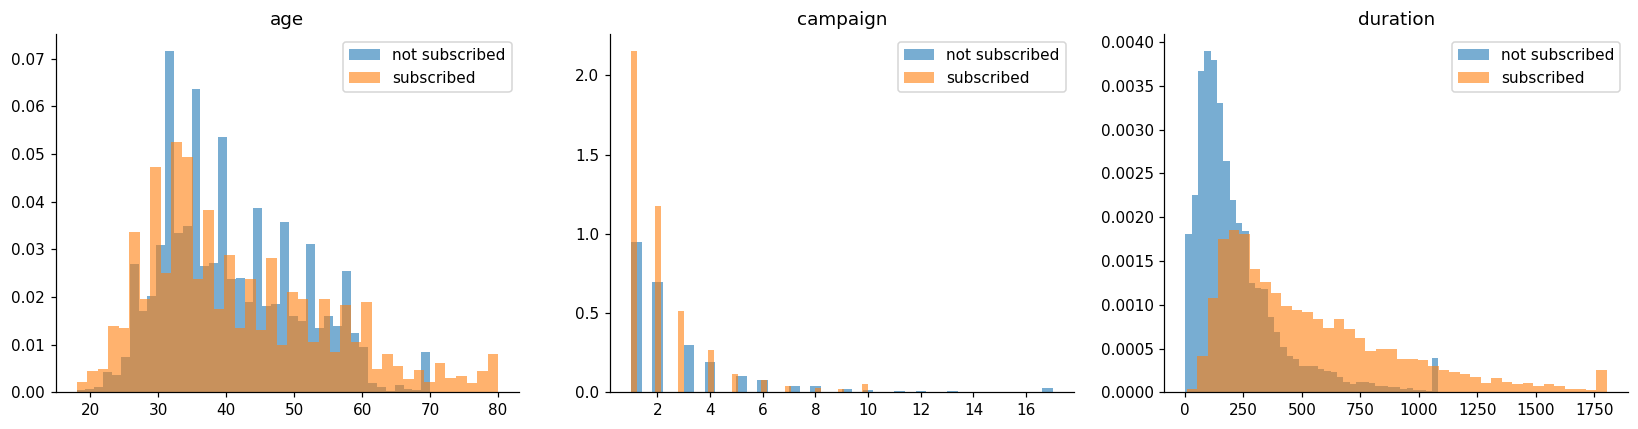

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "campaign", "duration"]):
    for label, grp in df.assign(y=y_all).groupby("y"):
        ax.hist(grp[col].clip(upper=grp[col].quantile(0.99)), bins=40, alpha=0.6,
                density=True, label="subscribed" if label else "not subscribed")
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_distributions.png", bbox_inches="tight"); plt.show()

**Observations**
- Customers whose **previous campaign succeeded** (`poutcome = success`) convert at a far higher rate — prior relationship is the strongest pre-call signal.
- **Cellular** contacts convert better than `unknown` contact type; conversion is strongly **seasonal** (low in May, the busiest month; high in Mar/Sep/Oct/Dec).
- More calls in the same campaign (`campaign`) → lower conversion: repeated calling has diminishing returns.
- `duration` separates the classes almost perfectly — **because it is an outcome of the call**, not a predictor available beforehand.

### Leakage decision
`duration` is only known after the call has ended (and a call of 0 seconds is always a "no"). Using it to decide *whom to call* is impossible in practice, so it is **excluded from all main models**. Section 10 measures how much it would have inflated the scores.

## 4. Train / test split and cross-validation

In [7]:
X = df.drop(columns=[TARGET] + LEAKY_COLS)
y = y_all

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X_train.shape, X_test.shape)

(8250, 15) (2750, 15)


- The **test set (25%) is never touched** until the final evaluation in Section 6; all model selection happens with cross-validation on the training set.
- `StratifiedKFold` keeps the yes/no ratio identical in every fold.
- All preprocessing lives **inside** the pipeline, so imputation medians and scalers are fit on each training fold only — no information from validation folds leaks into training.

## 5. Model comparison with hyper-parameter search

In [10]:
candidates = {
    "Baseline (most frequent)": (
        make_pipeline(DummyClassifier(strategy="most_frequent")), {}),
    "Logistic regression": (
        make_pipeline(LogisticRegression(max_iter=2000)),
        {"model__C": loguniform(1e-3, 1e2)}),
    "KNN": (
        make_pipeline(KNeighborsClassifier()),
        {"model__n_neighbors": randint(5, 80), "model__weights": ["uniform", "distance"]}),
    "Decision tree": (
        make_pipeline(DecisionTreeClassifier(random_state=SEED), scale_numeric=False),
        {"model__max_depth": randint(2, 12), "model__min_samples_leaf": randint(1, 60)}),
    "Random forest": (
        make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
                      scale_numeric=False),
        {"model__max_depth": randint(4, 20), "model__min_samples_leaf": randint(1, 20),
         "model__max_features": ["sqrt", 0.3, 0.5]}),
    "XGBoost": (
        make_pipeline(XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1),
                      scale_numeric=False),
        {"model__n_estimators": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.3),
         "model__max_depth": randint(2, 8), "model__subsample": uniform(0.6, 0.4),
         "model__colsample_bytree": uniform(0.5, 0.5), "model__min_child_weight": randint(1, 10)}),
}

fitted, cv_rows = {}, []
for name, (pipe, space) in candidates.items():
    if space:
        search = RandomizedSearchCV(pipe, space, n_iter=30, cv=cv, scoring="roc_auc",
                                    random_state=SEED, n_jobs=1)
        search.fit(X_train, y_train)
        best, cv_auc, cv_std = (search.best_estimator_, search.best_score_,
                                search.cv_results_["std_test_score"][search.best_index_])
        params = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                  for k, v in search.best_params_.items()}
    else:
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
        best, cv_auc, cv_std, params = pipe.fit(X_train, y_train), scores.mean(), scores.std(), {}
    fitted[name] = best
    cv_rows.append({"model": name, "CV ROC-AUC": cv_auc, "± std": cv_std, "best params": params})
    print(f"{name:28s} CV ROC-AUC = {cv_auc:.3f} ± {cv_std:.3f}")

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC", ascending=False)
cv_results

Baseline (most frequent)     CV ROC-AUC = 0.500 ± 0.000
Logistic regression          CV ROC-AUC = 0.770 ± 0.003


d:\python\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\python\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "d:\python\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\python\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "d:\python\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


KNN                          CV ROC-AUC = 0.770 ± 0.006
Decision tree                CV ROC-AUC = 0.755 ± 0.006
Random forest                CV ROC-AUC = 0.797 ± 0.006
XGBoost                      CV ROC-AUC = 0.805 ± 0.005


,model,CV ROC-AUC,± std,best params
5,XGBoost,0.805090,0.005499,"{'colsample_bytree': 0.8035, 'learning_rate': ..."
4,Random forest,0.796887,0.006205,"{'max_depth': 13, 'max_features': 'sqrt', 'min..."
2,KNN,0.769956,0.005892,"{'n_neighbors': 64, 'weights': 'distance'}"
1,Logistic regression,0.769560,0.003419,{'C': 0.4205}
3,Decision tree,0.755025,0.006387,"{'max_depth': 10, 'min_samples_leaf': 14}"
0,Baseline (most frequent),0.500000,0.000000,{}


**Why these choices**
- **Scoring = ROC-AUC**: the campaign ranks customers and calls from the top down, so what matters is ranking quality, not accuracy at an arbitrary 0.5 cut-off.
- **RandomizedSearchCV (30 draws)** over continuous distributions explores the space more efficiently than a small fixed grid.
- **Logistic regression** is included as the interpretable benchmark a bank would use by default: a complex model has to clearly beat it to be worth deploying.
- Tree-based models skip scaling (they are scale-invariant); KNN and logistic regression get standardised inputs.

## 6. Hold-out evaluation

In [11]:
proba = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
test_results = score_table(y_test, proba)
test_results.round(3)

,model,ROC-AUC,PR-AUC,Brier,F1@0.5
0,XGBoost,0.798,0.806,0.179,0.698
1,Random forest,0.789,0.792,0.185,0.692
2,KNN,0.765,0.760,0.196,0.644
3,Logistic regression,0.764,0.771,0.194,0.659
4,Decision tree,0.743,0.727,0.205,0.634
5,Baseline (most frequent),0.500,0.475,0.475,0.000


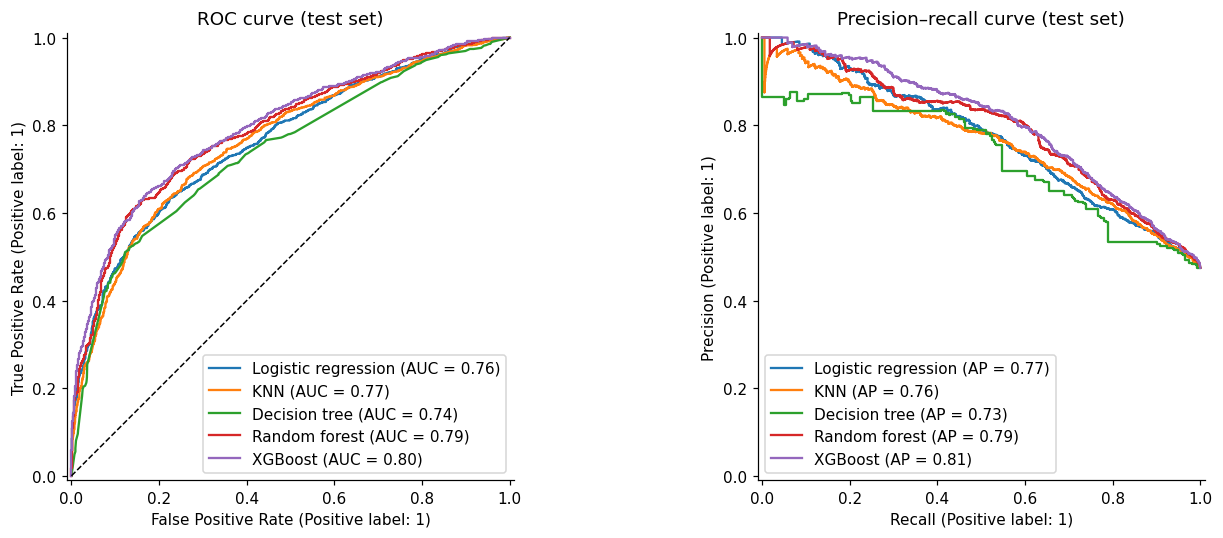

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, m in fitted.items():
    if name.startswith("Baseline"): continue
    RocCurveDisplay.from_predictions(y_test, proba[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve (test set)")
axes[1].set_title("Precision–recall curve (test set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/roc_pr_curves.png", bbox_inches="tight"); plt.show()

Selected model: XGBoost


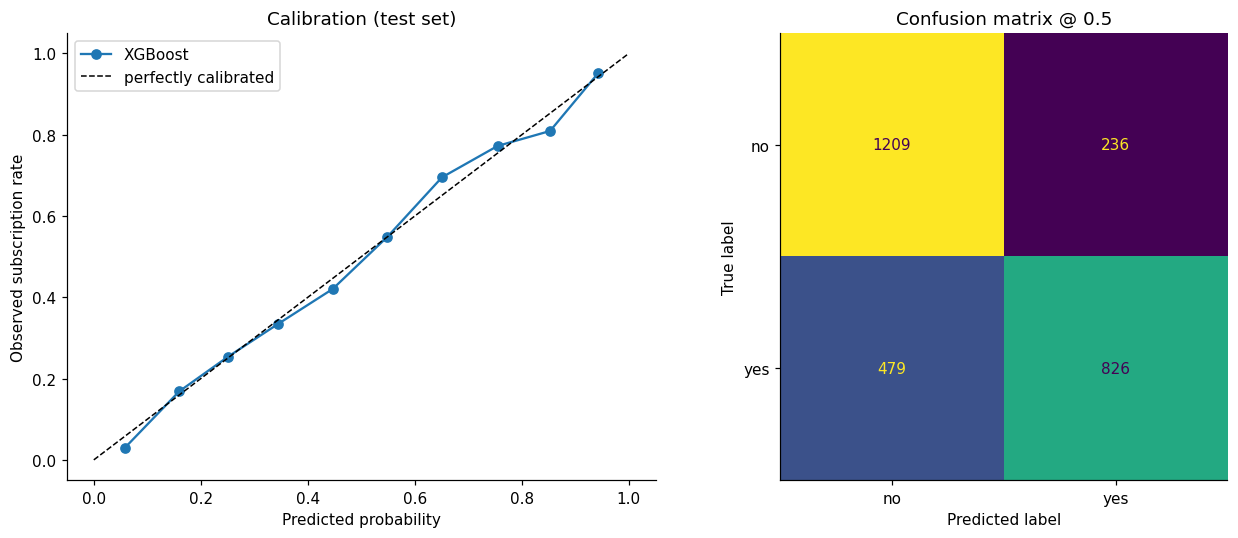

In [13]:
# Select on CROSS-VALIDATION score, not test score, so the test set stays an unbiased estimate.
best_name = cv_results.loc[cv_results["model"] != "Baseline (most frequent)", "model"].iloc[0]
best_model, p_best = fitted[best_name], proba[best_name]
print("Selected model:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
frac_pos, mean_pred = calibration_curve(y_test, p_best, n_bins=10)
axes[0].plot(mean_pred, frac_pos, "o-", label=best_name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
axes[0].set(xlabel="Predicted probability", ylabel="Observed subscription rate",
            title="Calibration (test set)"); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, (p_best >= 0.5).astype(int),
                                        display_labels=["no", "yes"], ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix @ 0.5")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/calibration_confusion.png", bbox_inches="tight"); plt.show()

- **Calibration** checks whether a predicted 70% really means ~70% of such customers subscribe. Well-calibrated probabilities are what allow the expected-profit calculation below.
- Cross-validated and hold-out scores should be close; a large gap would signal over-fitting during model selection.

## 7. Business impact — whom should we call?

In [14]:
gains = gains_table(y_test, p_best)
gains.round(3)

,customers,subscribers,pct_customers_called,pct_subscribers_reached,conversion_rate,cumulative_lift
decile,,,,,,
1,275,262,0.1,0.201,0.953,2.008
2,275,225,0.2,0.373,0.818,1.866
3,275,200,0.3,0.526,0.727,1.755
4,275,157,0.4,0.647,0.571,1.617
5,275,112,0.5,0.733,0.407,1.465
6,275,93,0.6,0.804,0.338,1.340
7,275,86,0.7,0.870,0.313,1.242
8,275,65,0.8,0.920,0.236,1.149
9,275,66,0.9,0.970,0.240,1.078


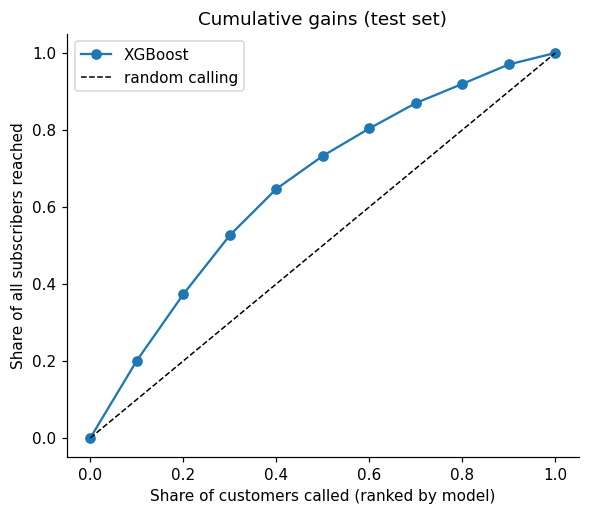

Calling the top 20% reaches 37% of subscribers (lift 1.87x)
Calling the top 30% reaches 53% of subscribers (lift 1.75x)


In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0] + gains["pct_customers_called"].tolist(),
        [0] + gains["pct_subscribers_reached"].tolist(), "o-", label=best_name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random calling")
ax.set(xlabel="Share of customers called (ranked by model)",
       ylabel="Share of all subscribers reached", title="Cumulative gains (test set)")
ax.legend(); plt.savefig(f"{FIG_DIR}/cumulative_gains.png", bbox_inches="tight"); plt.show()

top20 = gains.loc[2, "pct_subscribers_reached"]; top30 = gains.loc[3, "pct_subscribers_reached"]
print(f"Calling the top 20% reaches {top20:.0%} of subscribers (lift {gains.loc[2,'cumulative_lift']:.2f}x)")
print(f"Calling the top 30% reaches {top30:.0%} of subscribers (lift {gains.loc[3,'cumulative_lift']:.2f}x)")

### Expected-profit threshold
The cost of a call and the value of a deposit are **illustrative assumptions** (change them to the bank's real figures). The point is the method: pick the probability cut-off that maximises expected profit instead of defaulting to 0.5.

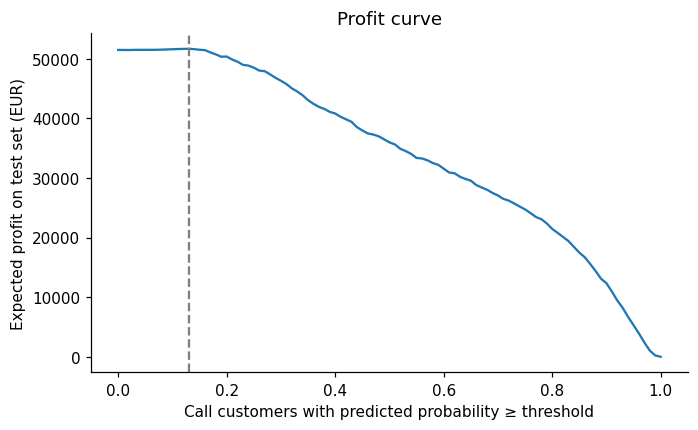

Best threshold: 0.13 → call 96% of customers
Profit: 51,695 EUR vs 51,500 EUR when calling everyone (+0%)


In [16]:
COST_PER_CALL = 5        # EUR, agent time — assumption
VALUE_PER_DEPOSIT = 50   # EUR, expected margin per new deposit — assumption

pc = profit_curve(y_test, p_best, COST_PER_CALL, VALUE_PER_DEPOSIT)
best_row = pc.loc[pc["profit"].idxmax()]
call_all = pc.loc[0, "profit"]
share_called = (p_best >= best_row.threshold).mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pc["threshold"], pc["profit"])
ax.axvline(best_row.threshold, ls="--", c="grey")
ax.set(xlabel="Call customers with predicted probability ≥ threshold",
       ylabel="Expected profit on test set (EUR)", title="Profit curve")
plt.savefig(f"{FIG_DIR}/profit_curve.png", bbox_inches="tight"); plt.show()

print(f"Best threshold: {best_row.threshold:.2f} → call {share_called:.0%} of customers")
print(f"Profit: {best_row.profit:,.0f} EUR vs {call_all:,.0f} EUR when calling everyone "
      f"({(best_row.profit - call_all) / abs(call_all):+.0%})")

## 8. Model explainability (SHAP)

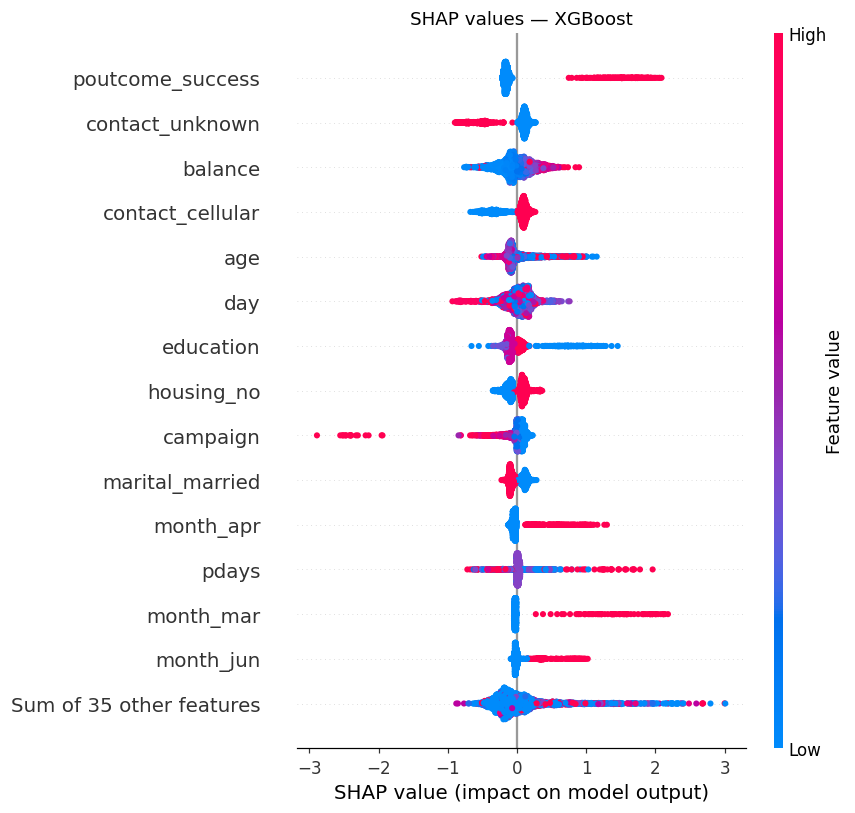

In [17]:
pre = best_model[:-1]                                   # feature engineering + preprocessing
X_test_t = pre.transform(X_test)
X_test_t = X_test_t.toarray() if hasattr(X_test_t, "toarray") else X_test_t
feat_names = best_model.named_steps["preprocess"].get_feature_names_out()
X_test_t = pd.DataFrame(X_test_t, columns=feat_names, index=X_test.index)

model = best_model.named_steps["model"]
if isinstance(model, (XGBClassifier, RandomForestClassifier, DecisionTreeClassifier)):
    explainer = shap.TreeExplainer(model)
else:
    explainer = shap.Explainer(model, X_test_t)
sv = explainer(X_test_t)
if sv.values.ndim == 3:                                 # some explainers return one slice per class
    sv = sv[:, :, 1]

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title(f"SHAP values — {best_name}"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/shap_summary.png", bbox_inches="tight"); plt.show()

In [18]:
shap_importance = (pd.DataFrame({"feature": feat_names, "mean_|SHAP|": np.abs(sv.values).mean(0)})
                   .sort_values("mean_|SHAP|", ascending=False).head(10).reset_index(drop=True))
shap_importance

,feature,mean_|SHAP|
0,poutcome_success,0.288553
1,contact_unknown,0.208020
2,balance,0.173674
3,contact_cellular,0.171521
4,age,0.149795
5,day,0.149736
6,education,0.131638
7,housing_no,0.111916
8,campaign,0.096770
9,marital_married,0.094488


**Reading the SHAP plot**: each dot is a customer; position to the right pushes the prediction towards "subscribe"; colour shows the feature value. This gives the marketing team actionable rules of thumb (e.g. prior success, contact channel, timing, how many times already called) instead of a black box.

## 9. Results summary and final model

In [19]:
summary = cv_results[["model", "CV ROC-AUC", "± std"]].merge(test_results, on="model")
summary.round(3)

,model,CV ROC-AUC,± std,ROC-AUC,PR-AUC,Brier,F1@0.5
0,XGBoost,0.805,0.005,0.798,0.806,0.179,0.698
1,Random forest,0.797,0.006,0.789,0.792,0.185,0.692
2,KNN,0.770,0.006,0.765,0.760,0.196,0.644
3,Logistic regression,0.770,0.003,0.764,0.771,0.194,0.659
4,Decision tree,0.755,0.006,0.743,0.727,0.205,0.634
5,Baseline (most frequent),0.500,0.000,0.500,0.475,0.475,0.000


In [20]:
# Refit the selected pipeline on ALL data for deployment and save it.
final_model = best_model.fit(X, y)
os.makedirs("../models", exist_ok=True)
joblib.dump(final_model, "../models/term_deposit_model.joblib")

# Sanity check: the saved artefact loads and scores new rows.
reloaded = joblib.load("../models/term_deposit_model.joblib")
reloaded.predict_proba(X.head(3))[:, 1].round(3)

array([0.191, 0.116, 0.146], dtype=float32)

## 10. Appendix — how much did `duration` leak?
Same best model type, same split, but with `duration` added back. The gap is the score that would have been **reported but never achieved** in a real campaign.

In [21]:
from sklearn.base import clone
X_leak = df.drop(columns=[TARGET])
Xl_train, Xl_test = X_leak.loc[X_train.index], X_leak.loc[X_test.index]

leaky = make_pipeline(clone(best_model.named_steps["model"]),
                      scale_numeric=best_model.named_steps["preprocess"]
                          .named_transformers_["num"].named_steps.get("scale") is not None,
                      include_duration=True)
leaky.fit(Xl_train, y_train)
p_leak = leaky.predict_proba(Xl_test)[:, 1]

score_table(y_test, {f"{best_name} without duration (honest)": p_best,
                     f"{best_name} WITH duration (leaky)": p_leak}).round(3)

,model,ROC-AUC,PR-AUC,Brier,F1@0.5
0,XGBoost WITH duration (leaky),0.921,0.894,0.107,0.851
1,XGBoost without duration (honest),0.798,0.806,0.179,0.698


## 11. Limitations and next steps
- Data comes from one bank (2008–2010); conversion patterns (e.g. seasonality, interest-rate environment) may not transfer.
- The cost/value figures in Section 7 are placeholders; with real unit economics the threshold should be re-optimised.
- Next: an uplift model (who converts *because* of the call), and monitoring for drift if deployed.